# Practical 10: Backpropagation Neural Network and K-means

Use scikit-learn MLPClassifier for supervised neural-network classification trained with backpropagation, and KMeans for unsupervised clustering. This notebook contains its own full implementation.

## Load data and create a holdout split

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, silhouette_score
from sklearn.cluster import KMeans

df = pd.read_csv(Path("heart attack analysis.csv"))
X = df.drop(columns="output")
y = df["output"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Dataset shape:", df.shape, "Missing values:", int(df.isna().sum().sum()))

Dataset shape: (303, 14) Missing values: 0


## Backpropagation neural network with sklearn

`MLPClassifier` trains its weights through backpropagation. Report holdout performance and visualize its confusion matrix.

Holdout accuracy: 0.7236842105263158
              precision    recall  f1-score   support

           0       0.72      0.66      0.69        35
           1       0.73      0.78      0.75        41

    accuracy                           0.72        76
   macro avg       0.72      0.72      0.72        76
weighted avg       0.72      0.72      0.72        76



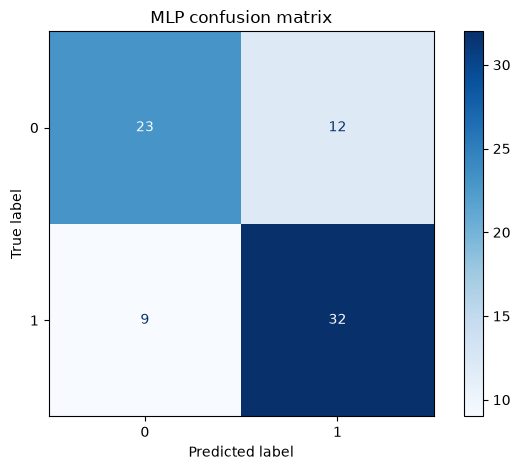

In [7]:
mlp = MLPClassifier(hidden_layer_sizes=(16, 8), activation="relu", solver="lbfgs",
                    max_iter=2000, random_state=42)
mlp.fit(X_train_scaled, y_train)
mlp_pred = mlp.predict(X_test_scaled)
print("Holdout accuracy:", accuracy_score(y_test, mlp_pred))
print(classification_report(y_test, mlp_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, mlp_pred, cmap="Blues")
plt.title("MLP confusion matrix"); plt.tight_layout(); plt.show()

## Inspect a two-cluster solution

In [6]:
kmeans = KMeans(n_clusters=2, n_init=20, random_state=42)
cluster_labels = kmeans.fit_predict(X_cluster)
print("Cluster sizes:", np.bincount(cluster_labels))
print("Silhouette score:", silhouette_score(X_cluster, cluster_labels))
print("Cluster versus target (descriptive only):")
display(pd.crosstab(pd.Series(cluster_labels, name="cluster"), y, colnames=["output"]))

Cluster sizes: [105 198]
Silhouette score: 0.16823269494218376
Cluster versus target (descriptive only):


output,0,1
cluster,,
0,93,12
1,45,153
